In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [2]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [3]:
# specific

from sklearn.decomposition import PCA, TruncatedSVD
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

In [4]:
importlib.reload(read_utils)

<module 'utils_mouse.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-2019-stringer/notebooks/analysis/../../src/utils_mouse/read_utils.py'>

In [5]:
ll = 'll00'
data_variant = 'gcamp'

In [6]:
# specific

model_variant = 'ss'
organism = 'mouse'
manual = False
full = True

In [7]:
file_id = 2
save = True

In [8]:
max_noi = 20
neurons_of_interest = []
bhl_selection = analysis_utils.get_class_labels(organism)

In [9]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filename, traces, behavior, classes, timestamps, aux = analysis_utils.read_data(organism, file_id)
metadata = (filename, model_path, model_variant, data_variant, manual, full)

significant_impr = analysis_utils.get_significant_neurons(filename, model_variant, mode='impr')
significant_impr = dict(sorted(dict(significant_impr).items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

significant_neurons = analysis_utils.get_significant_neurons(filename, model_variant, mode='hgm')
significant_neurons = dict(sorted(dict(significant_neurons).items(), key=lambda x: x[1][1] - x[1][0], reverse=True))

neuron_labels = (list(significant_impr.keys()) + [label for label in significant_neurons.keys() if label not in significant_impr])[:max_noi]
for neuron in neurons_of_interest:
	if neuron not in neuron_labels and neuron in traces.columns:
		neuron_labels.append(neuron)

In [10]:
bom_params, hgm_params = analysis_utils.read_models(*metadata)

((_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(*metadata)

bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

In [11]:
path = os.path.join(os.path.expanduser('~'), 'Desktop/DATA/mouse-2019-stringer/6163622/sessions')
med = sp.io.loadmat(os.path.join(path, 'spont_M160907_MP028_2016-09-26'), variable_names=['med'])['med']

In [12]:
# sig_neurons = dict()
# for label in traces:
# 	if label in significant_neurons:
# 		sig_neurons[label] = np.array([
# 			significant_neurons[label].values[0].item(),
# 			significant_neurons[label].values[1].item()
# 		])
#
# colors_keys = list(sig_neurons.keys())
# colors_values = np.array([val[1] for val in sig_neurons.values()])
# colors_values = (colors_values - colors_values.min()) / (colors_values.max() - colors_values.min())
# colors = {key: value for key, value in zip(colors_keys, colors_values)}
#
# for label in traces:
# 	if label not in significant_neurons:
# 		colors[label] = 'gray'
#
# colors = dict(sorted(colors.items(), key=lambda x: x[0].split('_')[1]))
#
# colors = [((0. if color != 'gray' else 0.2),
# 		   (color if color != 'gray' else 0.2),
# 		   (0. if color != 'gray' else 0.2),
# 		   (0.1 if color == 'gray' else 1)) for color in colors.values()]

In [13]:
# fig = plt.figure(figsize=(10, 10))
# ax = fig.add_subplot(111, projection='3d')
#
# ax.scatter(med[:, 0], med[:, 1], med[:, 2], c=colors, marker='o', s=10)
#
# ax.set_xlabel("X")
# ax.set_ylabel("Y")
# ax.set_zlabel("Z")
#
# plt.savefig(os.path.join(os.path.expanduser('~'), 'Desktop/loc.png'), bbox_inches='tight', dpi=300)
# plt.show()

In [14]:
sig_neurons = dict()
for label in traces:
	if label in significant_impr:
		sig_neurons[label] = np.array(significant_impr[label].values[1].item() - significant_impr[label].values[0].item())

colors_keys = list(sig_neurons.keys())
colors_values = np.array([val for val in sig_neurons.values()])

colors_values = (colors_values - colors_values.min()) / (colors_values.max() - colors_values.min())
colors = {key: value for key, value in zip(colors_keys, colors_values)}

for label in traces:
	if label not in significant_impr:
		colors[label] = 'gray'

colors = dict(sorted(colors.items(), key=lambda x: x[0].split('_')[1]))

colors = [((0. if color != 'gray' else 0.2),
		   (color if color != 'gray' else 0.2),
		   (0. if color != 'gray' else 0.2),
		   (0.1 if color == 'gray' else 1)) for color in colors.values()]

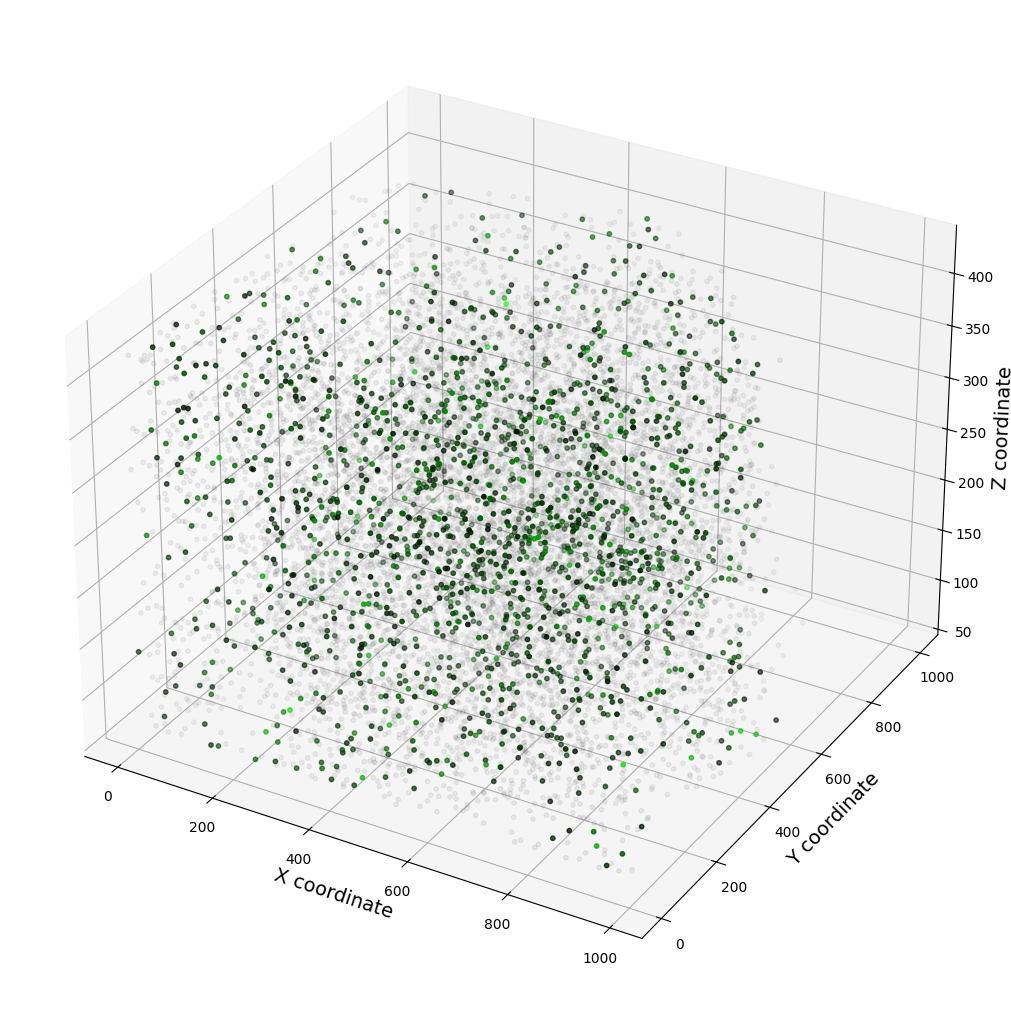

In [17]:
fig = plt.figure(figsize=(10, 10), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')

ax.scatter(med[:, 0], med[:, 1], med[:, 2], c=colors, marker='o', s=10)

ax.set_xlabel("X coordinate", fontsize=14)
ax.set_ylabel("Y coordinate", fontsize=14)
ax.set_zlabel("Z coordinate", fontsize=14)

plt.savefig(os.path.join(os.path.expanduser('~'), 'Desktop/loc_impr.png'), bbox_inches='tight', dpi=300)
plt.show()